##  CELLULE 1 — Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from wordcloud import WordCloud
from collections import Counter
from pathlib import Path
from tqdm import tqdm
from langdetect import detect, DetectorFactory, LangDetectException
import html, re, os, warnings

warnings.filterwarnings('ignore')
DetectorFactory.seed = 42
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 120

BASE_DIR     = Path(os.getcwd()).parent
RAW_DIR      = BASE_DIR / 'data' / 'raw'
PROC_DIR     = BASE_DIR / 'data' / 'processed'
FIGURES_DIR  = BASE_DIR / 'outputs' / 'figures'
PROC_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("✅ Prêt")
print(f"Données brutes : {RAW_DIR}")

✅ Prêt
Données brutes : c:\Users\Tariq.ouhsine\OneDrive - Exens Solutions\Bureau\rakuten\data\raw


##  CELLULE 2 — Chargement & Fusion

In [2]:
X = pd.read_csv(RAW_DIR / 'X_train.csv', index_col=0)
Y = pd.read_csv(RAW_DIR / 'Y_train.csv', index_col=0)

df = X.join(Y, how='inner')
assert df.shape[0] == X.shape[0], "Problème de jointure"

print(f"Dataset fusionné : {df.shape[0]:,} produits × {df.shape[1]} variables")
print(f"\n{df.dtypes}")
print(f"\nValeurs manquantes :")
print(df.isnull().sum())
display(df.sample(5, random_state=42))

Dataset fusionné : 84,916 produits × 5 variables

designation    object
description    object
productid       int64
imageid         int64
prdtypecode     int64
dtype: object

Valeurs manquantes :
designation        0
description    29800
productid          0
imageid            0
prdtypecode        0
dtype: int64


,designation,description,productid,imageid,prdtypecode
36138,Nk Pro Racing - Jeu En Téléchargement,<strong>À PROPOS DU JEU</strong> <b>NKPro Rac...,1711734527,1100082580,2905
68630,Exit - Tombeau Du Pharaon,"<div class=""rte""><p>EXIT est un jeu qui repren...",2397542298,1139624392,1281
36172,Bricolage Lettres En Mousse D'argent Alphabet ...,Bricolage lettres en mousse d&#39;argent Alpha...,3979577549,1271697301,2060
9830,Nostalgique Fer Blanc Clockwork Chaîne Jouet P...,Nostalgique fer blanc Clockwork chaîne Jouet P...,4197657726,1313204688,1280
28422,Le Courrier De L'unesco Mai 1996 N° 9605 : Le...,NaN,52594358,518749844,2280


## CELLULE 3 — Mapping des codes produit

In [3]:
CODE2LABEL = {
    10:'Livre occasion', 40:'Jeu vidéo & accessoires', 50:'Accessoire Console',
    60:'Console de jeu', 1140:'Figurine', 1160:'Carte Collection',
    1180:'Jeu de plateau', 1280:'Jouet enfant & déguisement',
    1281:'Jeu de société', 1300:'Jouet technologique', 1301:'Chaussettes',
    1302:'Jeu extérieur & vêtement', 1320:'Puériculture', 1560:'Mobilier intérieur',
    1920:'Literie & chambre', 1940:'Cuisine', 2060:'Décoration intérieure',
    2220:'Animalerie', 2280:'Revues & journaux', 2403:'Magazines & BD',
    2462:'Jeu occasion', 2522:'Bureautique & papeterie', 2582:'Mobilier extérieur',
    2583:'Piscine & jardin', 2585:'Bricolage', 2705:'Livre neuf', 2905:'Jeu PC',
}

df['categorie'] = df['prdtypecode'].map(CODE2LABEL)
print(f"27 catégories mappées ✅")
display(df[['prdtypecode','categorie']].drop_duplicates().sort_values('prdtypecode'))

27 catégories mappées ✅


,prdtypecode,categorie
0,10,Livre occasion
31,40,Jeu vidéo & accessoires
2,50,Accessoire Console
40,60,Console de jeu
18,1140,Figurine
29,1160,Carte Collection
22,1180,Jeu de plateau
3,1280,Jouet enfant & déguisement
12,1281,Jeu de société
24,1300,Jouet technologique


## CELLULE 4 — Analyse des doublons

In [4]:
print("── Doublons ──────────────────────────────────")
print(f"Lignes identiques         : {df.duplicated().sum()}")
print(f"Désignations dupliquées   : {df['designation'].duplicated().sum()}")
print(f"Descriptions dupliquées*  : "
      f"{df.dropna(subset=['description'])['description'].duplicated().sum()}"
      f"  (*hors NaN)")
print(f"Doublons (design+desc)    : "
      f"{df[['designation','description']].dropna().duplicated().sum()}")
print(f"\nProductid uniques : {df['productid'].nunique():,}")
print(f"Imageid uniques   : {df['imageid'].nunique():,}")
print("\n→ Décision : doublons conservés, volume faible et images potentiellement distinctes")

── Doublons ──────────────────────────────────
Lignes identiques         : 0
Désignations dupliquées   : 2651
Descriptions dupliquées*  : 7610  (*hors NaN)
Doublons (design+desc)    : 1294

Productid uniques : 84,916
Imageid uniques   : 84,916

→ Décision : doublons conservés, volume faible et images potentiellement distinctes


## CELLULE 5 — Distribution de la variable cible

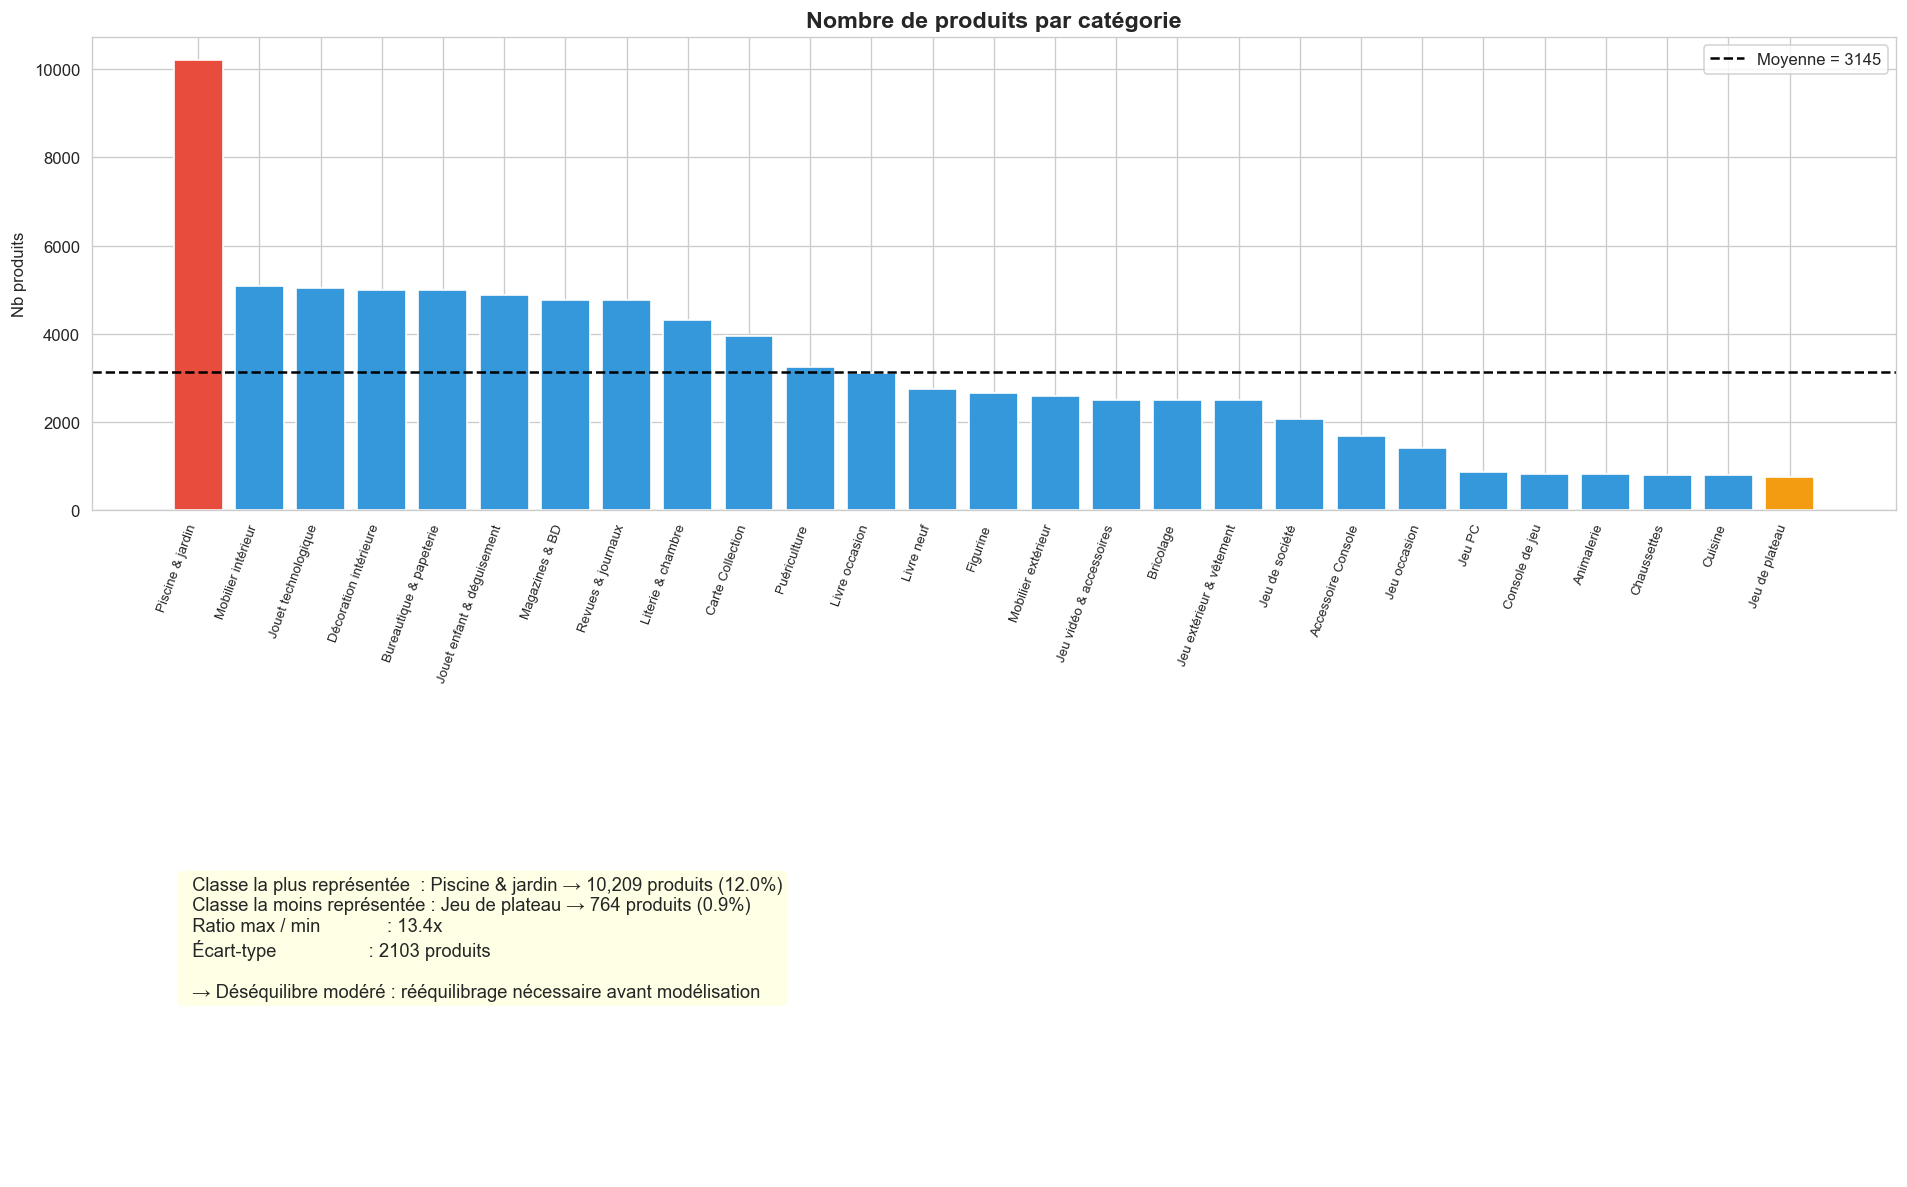

In [5]:
counts = df['prdtypecode'].value_counts().sort_values(ascending=False)
labels = [CODE2LABEL.get(c, str(c)) for c in counts.index]

fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Barplot
colors = ['#e74c3c' if v == counts.max() else
          '#f39c12' if v == counts.min() else '#3498db'
          for v in counts.values]
axes[0].bar(range(len(counts)), counts.values, color=colors, edgecolor='white')
axes[0].set_xticks(range(len(counts)))
axes[0].set_xticklabels(labels, rotation=70, ha='right', fontsize=8)
axes[0].axhline(counts.mean(), color='black', linestyle='--', linewidth=1.5,
                label=f'Moyenne = {counts.mean():.0f}')
axes[0].set_title("Nombre de produits par catégorie", fontsize=14, fontweight='bold')
axes[0].set_ylabel("Nb produits")
axes[0].legend()

# Stats déséquilibre
axes[1].axis('off')
stats_text = (
    f"  Classe la plus représentée  : {CODE2LABEL[counts.idxmax()]} "
    f"→ {counts.max():,} produits ({counts.max()/len(df)*100:.1f}%)\n"
    f"  Classe la moins représentée : {CODE2LABEL[counts.idxmin()]} "
    f"→ {counts.min():,} produits ({counts.min()/len(df)*100:.1f}%)\n"
    f"  Ratio max / min             : {counts.max()/counts.min():.1f}x\n"
    f"  Écart-type                  : {counts.std():.0f} produits\n\n"
    f"  → Déséquilibre modéré : rééquilibrage nécessaire avant modélisation"
)
axes[1].text(0.05, 0.5, stats_text, transform=axes[1].transAxes,
             fontsize=11, verticalalignment='center',
             bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

plt.tight_layout()
plt.savefig(FIGURES_DIR / '01_distribution_classes.png', bbox_inches='tight')
plt.show()

## CELLULE 6 — Analyse des valeurs manquantes (description)

In [6]:
pct_missing = df['description'].isna().mean() * 100

# Par catégorie
nan_by_cat = df.groupby('categorie').agg(
    total=('description', 'count'),
    avec_desc=('description', 'count'),
    sans_desc=('description', lambda x: x.isna().sum())
).reset_index()
nan_by_cat['pct_sans'] = (nan_by_cat['sans_desc'] / 
                           (nan_by_cat['avec_desc'] + nan_by_cat['sans_desc']) * 100)
nan_by_cat = nan_by_cat.sort_values('pct_sans', ascending=False)

fig = go.Figure()
fig.add_trace(go.Bar(
    name='Avec description',
    x=nan_by_cat['categorie'],
    y=100 - nan_by_cat['pct_sans'],
    marker_color='#27ae60'
))
fig.add_trace(go.Bar(
    name='Sans description (NaN)',
    x=nan_by_cat['categorie'],
    y=nan_by_cat['pct_sans'],
    marker_color='#e74c3c'
))
fig.update_layout(
    barmode='stack',
    title=f"Champ 'description' : {pct_missing:.1f}% de valeurs manquantes — répartition par catégorie",
    xaxis_tickangle=50,
    yaxis_title="% de produits",
    height=500,
    legend=dict(orientation='h', y=1.1)
)
fig.show()
fig.write_html(str(FIGURES_DIR / '02_missing_description.html'))

print(f"\n→ {pct_missing:.1f}% de descriptions manquantes")
print("→ Certaines catégories (ex. Livres) ont quasi 100% de NaN")
print("→ Suppression impossible → on concatène designation + description")


→ 35.1% de descriptions manquantes
→ Certaines catégories (ex. Livres) ont quasi 100% de NaN
→ Suppression impossible → on concatène designation + description


## CELLULE 7 — Distribution des longueurs de texte

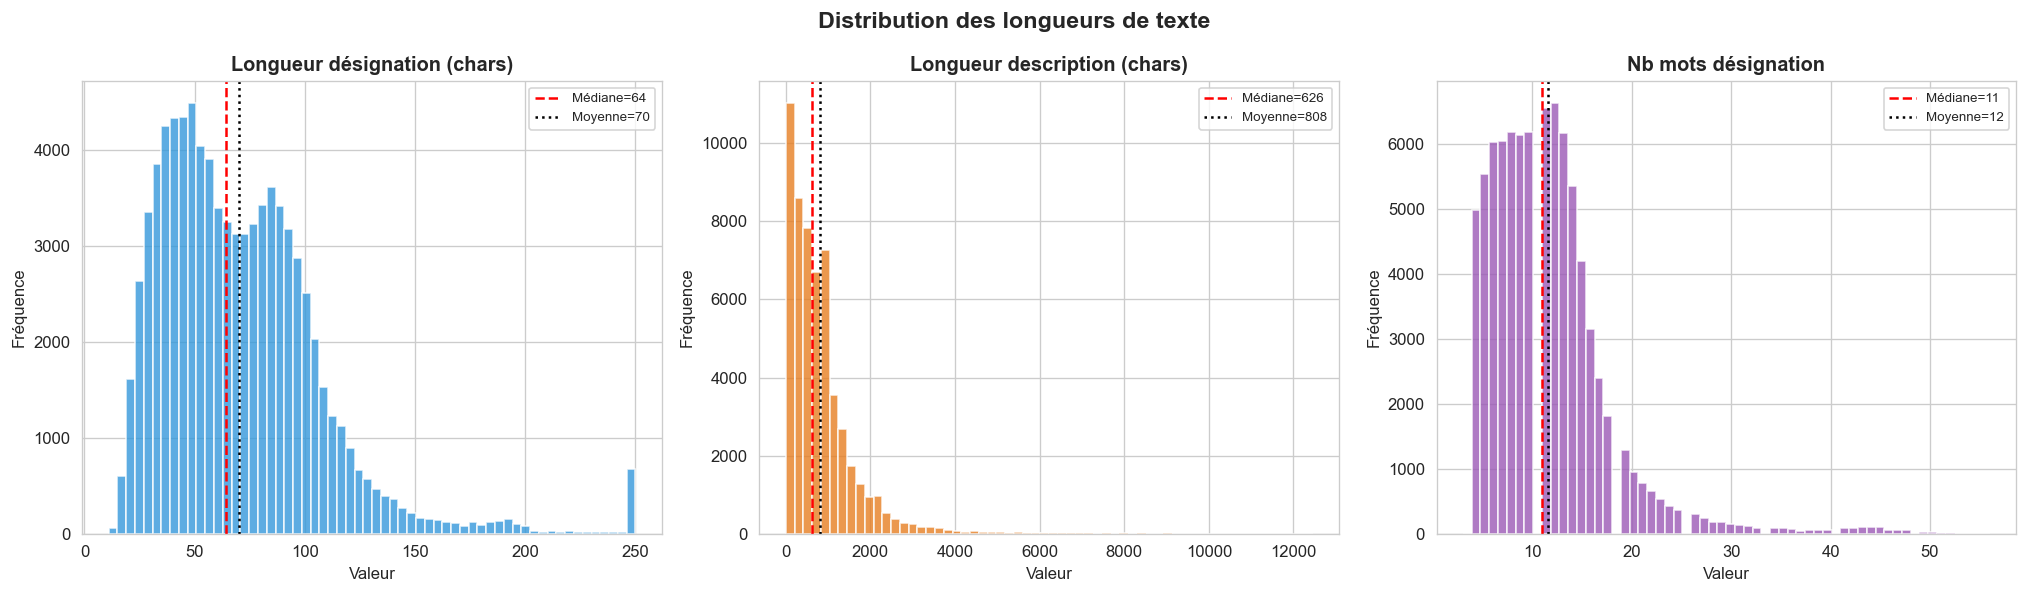

Descriptions très courtes (< 5 chars) : 70 produits


In [7]:
df['len_designation'] = df['designation'].str.len()
df['len_description'] = df['description'].str.len()
df['nb_mots_desig']   = df['designation'].str.split().str.len()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, col, color, title in zip(
    axes,
    ['len_designation', 'len_description', 'nb_mots_desig'],
    ['#3498db', '#e67e22', '#9b59b6'],
    ['Longueur désignation (chars)', 'Longueur description (chars)', 'Nb mots désignation']
):
    data = df[col].dropna()
    ax.hist(data, bins=60, color=color, alpha=0.8, edgecolor='white')
    ax.axvline(data.median(), color='red', linestyle='--',
               label=f'Médiane={data.median():.0f}')
    ax.axvline(data.mean(), color='black', linestyle=':',
               label=f'Moyenne={data.mean():.0f}')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel("Valeur")
    ax.set_ylabel("Fréquence")
    ax.legend(fontsize=8)

plt.suptitle("Distribution des longueurs de texte", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_longueurs_texte.png', bbox_inches='tight')
plt.show()

print(f"Descriptions très courtes (< 5 chars) : "
      f"{(df['len_description'] < 5).sum()} produits")

## CELLULE 8 — Nettoyage HTML

In [8]:
def nettoyer_html(texte):
    if pd.isna(texte):
        return texte
    # Balises de structure → retour à la ligne
    texte = re.sub(r'<\s*(?:br|p|li|div)[^>]*>', ' ', texte, flags=re.IGNORECASE)
    # Autres balises → espace
    texte = re.sub(r'<[^>]+>', ' ', texte)
    # Entités HTML → caractères normaux
    texte = html.unescape(texte)
    # Nettoyage des espaces
    return re.sub(r'\s+', ' ', texte).strip()

# Analyse avant nettoyage
regex_balise  = re.compile(r'<[^>]+>')
regex_entites = re.compile(r'&(?:#\d+|\w+);')
desc_non_null = df['description'].dropna()

pct_balises  = desc_non_null.str.contains(regex_balise).mean()  * 100
pct_entites  = desc_non_null.str.contains(regex_entites).mean() * 100

print(f"Descriptions avec balises HTML  : {pct_balises:.1f}%")
print(f"Descriptions avec entités HTML  : {pct_entites:.1f}%")
print(f"Désignations avec entités HTML  : "
      f"{df['designation'].str.contains(regex_entites).sum()} produits\n")

print("⏳ Nettoyage HTML...")
df['designation'] = df['designation'].apply(nettoyer_html)
df['description'] = df['description'].apply(nettoyer_html)
print("✅ Nettoyage terminé")

Descriptions avec balises HTML  : 28.4%
Descriptions avec entités HTML  : 63.6%
Désignations avec entités HTML  : 990 produits

⏳ Nettoyage HTML...
✅ Nettoyage terminé


## CELLULE 9 — Concaténation & détection de langue

In [ ]:
# Concaténation designation + description
df['description'] = df['description'].fillna('')
df['text'] = df['designation'] + ' ' + df['description']
df['text'] = df['text'].str.strip()

# Détection langue (avec cache)
LANG_CACHE = PROC_DIR / 'lang.csv'

if LANG_CACHE.exists():
    print(f"📂 Chargement cache langue : {LANG_CACHE}")
    lang_df = pd.read_csv(LANG_CACHE, index_col=0)
    df = df.join(lang_df[['lang']], how='left')
else:
    print("⏳ Détection des langues (~15 min)...")
    langues = []
    for texte in tqdm(df['text']):
        try:
            langues.append(detect(str(texte)))
        except LangDetectException:
            langues.append('unknown')
    df['lang'] = langues
    df[['lang']].to_csv(LANG_CACHE)
    print(f"✅ Cache sauvegardé → {LANG_CACHE}")

print(f"\nDistribution des langues :")
print(df['lang'].value_counts().head(8))

📂 Chargement cache langue : c:\Users\Tariq.ouhsine\OneDrive - Exens Solutions\Bureau\rakuten\data\processed\lang.csv

Distribution des langues :
lang
fr    65152
en    12332
de     2697
nl     1106
ca      778
it      640
ro      353
es      330
Name: count, dtype: int64


## CELLULE 10 — Visualisation des langues

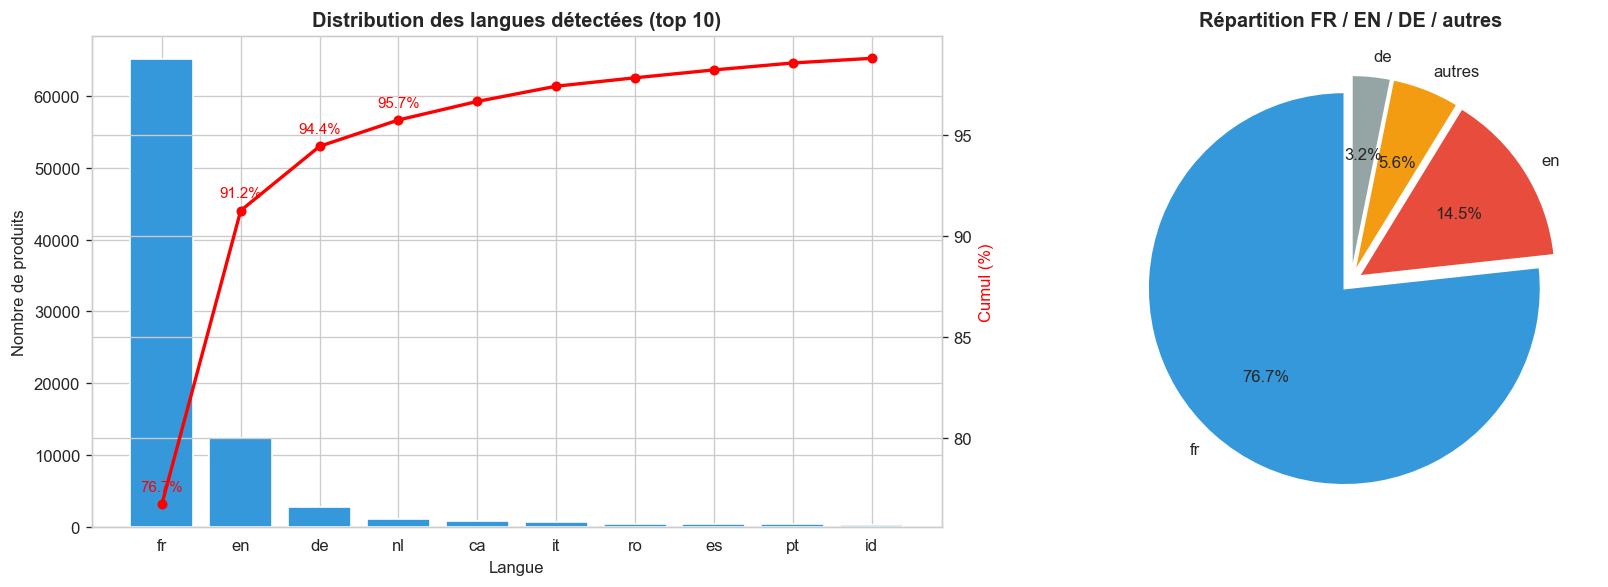


→ 3 langues dominantes : FR (77%), EN (15%), DE (3%)
→ Solution retenue : traduction vers le français


In [18]:
lang_counts = df['lang'].value_counts()
top3 = lang_counts.index[:3].tolist()
lang_simple = df['lang'].apply(lambda x: x if x in top3 else 'autres')
pie_data = lang_simple.value_counts()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Barplot avec cumul
cumul = (lang_counts / lang_counts.sum()).cumsum() * 100
ax2 = axes[0].twinx()
axes[0].bar(lang_counts.index[:10], lang_counts.values[:10],
            color='#3498db', edgecolor='white')
ax2.plot(lang_counts.index[:10], cumul.values[:10],
         'r-o', linewidth=2, markersize=5)
ax2.set_ylabel('Cumul (%)', color='red')
axes[0].set_title("Distribution des langues détectées (top 10)", fontweight='bold')
axes[0].set_xlabel("Langue")
axes[0].set_ylabel("Nombre de produits")

for i, (pct, idx) in enumerate(zip(cumul.values[:4], lang_counts.index[:4])):
    ax2.annotate(f'{pct:.1f}%', (idx, pct), textcoords='offset points',
                 xytext=(0, 8), ha='center', color='red', fontsize=9)

# Camembert
colors_pie = ['#3498db', '#e74c3c', '#f39c12', '#95a5a6']
axes[1].pie(pie_data.values, labels=pie_data.index,
            autopct='%1.1f%%', colors=colors_pie,
            startangle=90, explode=[0.05]*len(pie_data))
axes[1].set_title("Répartition FR / EN / DE / autres", fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_distribution_langues.png', bbox_inches='tight')
plt.show()

print(f"\n→ 3 langues dominantes : FR ({lang_counts.get('fr',0)/len(df)*100:.0f}%)"
      f", EN ({lang_counts.get('en',0)/len(df)*100:.0f}%)"
      f", DE ({lang_counts.get('de',0)/len(df)*100:.0f}%)")
print("→ Solution retenue : traduction vers le français")

## CELLULE 11 — Répartition langues par catégorie

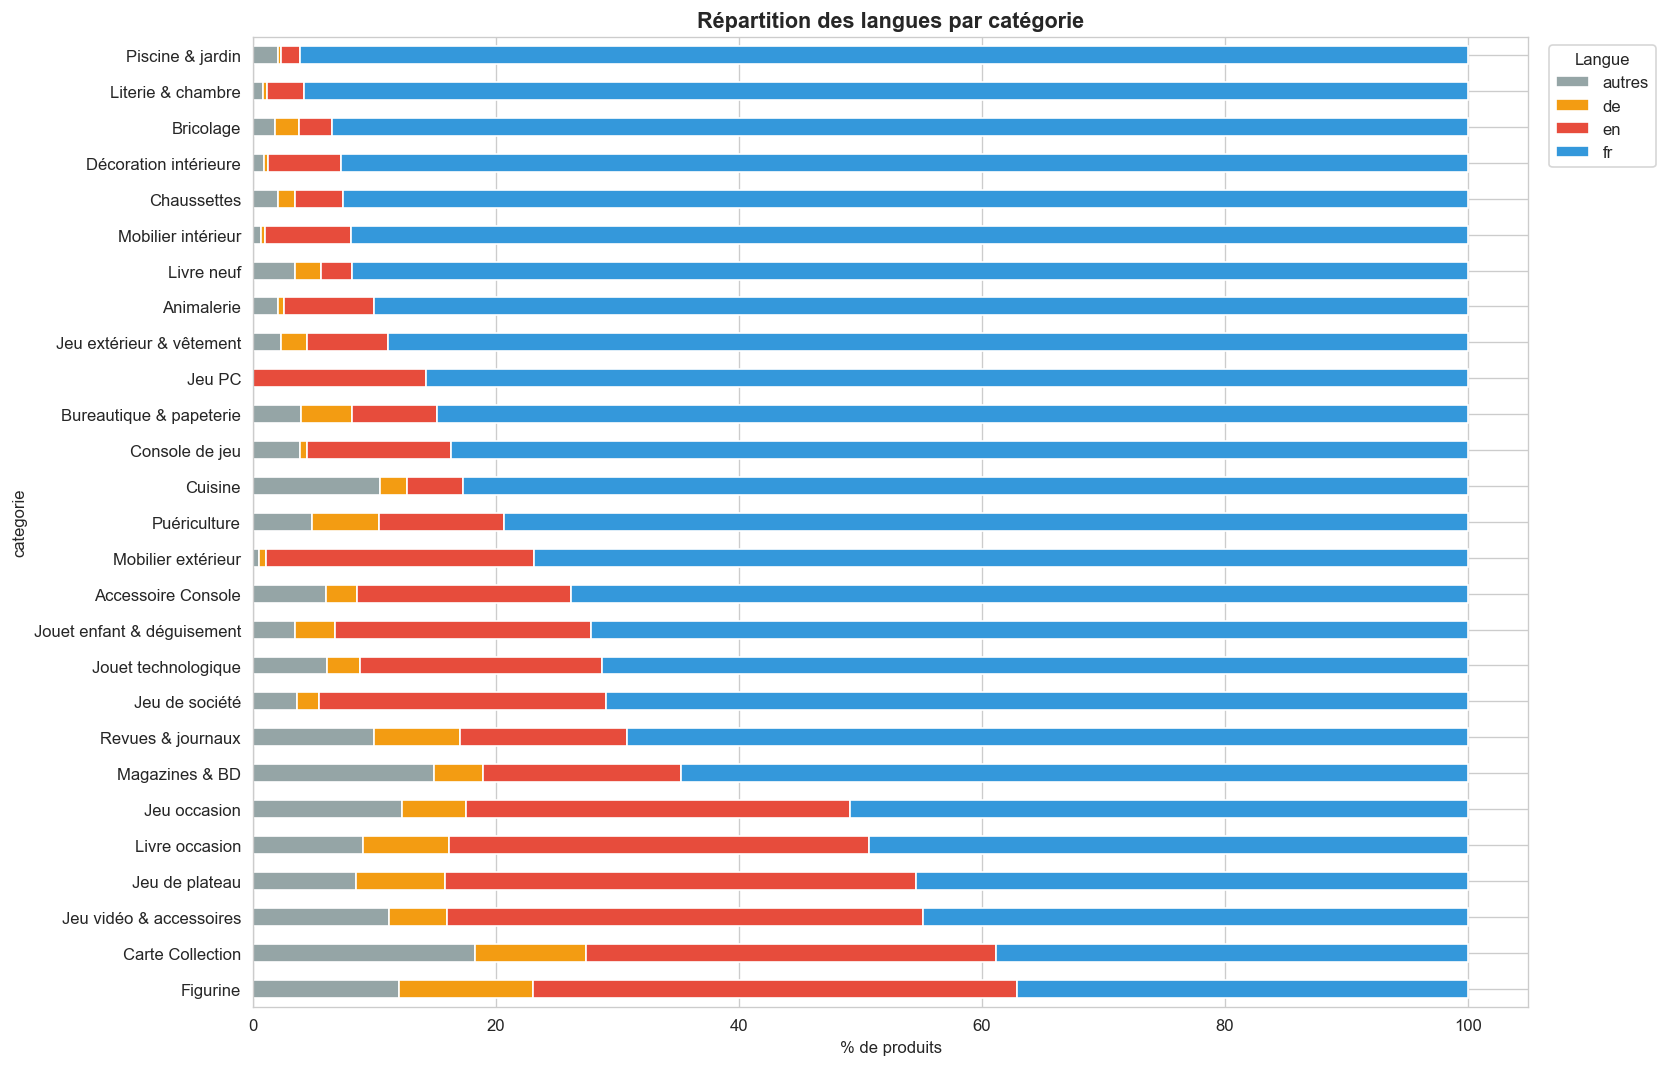

→ Le français est majoritaire dans toutes les catégories
→ Impossible de supprimer les autres langues sans déséquilibrer certaines classes


In [12]:
lang_by_cat = df.groupby(['categorie','lang']).size().reset_index(name='count')
lang_by_cat['lang_group'] = lang_by_cat['lang'].apply(
    lambda x: x if x in ['fr','en','de'] else 'autres')
pivot = lang_by_cat.groupby(['categorie','lang_group'])['count'].sum().unstack(fill_value=0)
pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100
pivot_pct = pivot_pct.sort_values('fr', ascending=True)

pivot_pct.plot(kind='barh', stacked=True, figsize=(14, 9),
               color={'fr':'#3498db','en':'#e74c3c',
                      'de':'#f39c12','autres':'#95a5a6'})
plt.title("Répartition des langues par catégorie", fontsize=13, fontweight='bold')
plt.xlabel("% de produits")
plt.legend(title='Langue', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig(FIGURES_DIR / '05_langues_par_categorie.png', bbox_inches='tight')
plt.show()

print("→ Le français est majoritaire dans toutes les catégories")
print("→ Impossible de supprimer les autres langues sans déséquilibrer certaines classes")

## CELLULE 12 — Extraction de mots & WordCloud global

⏳ Extraction des mots
✅ Terminé


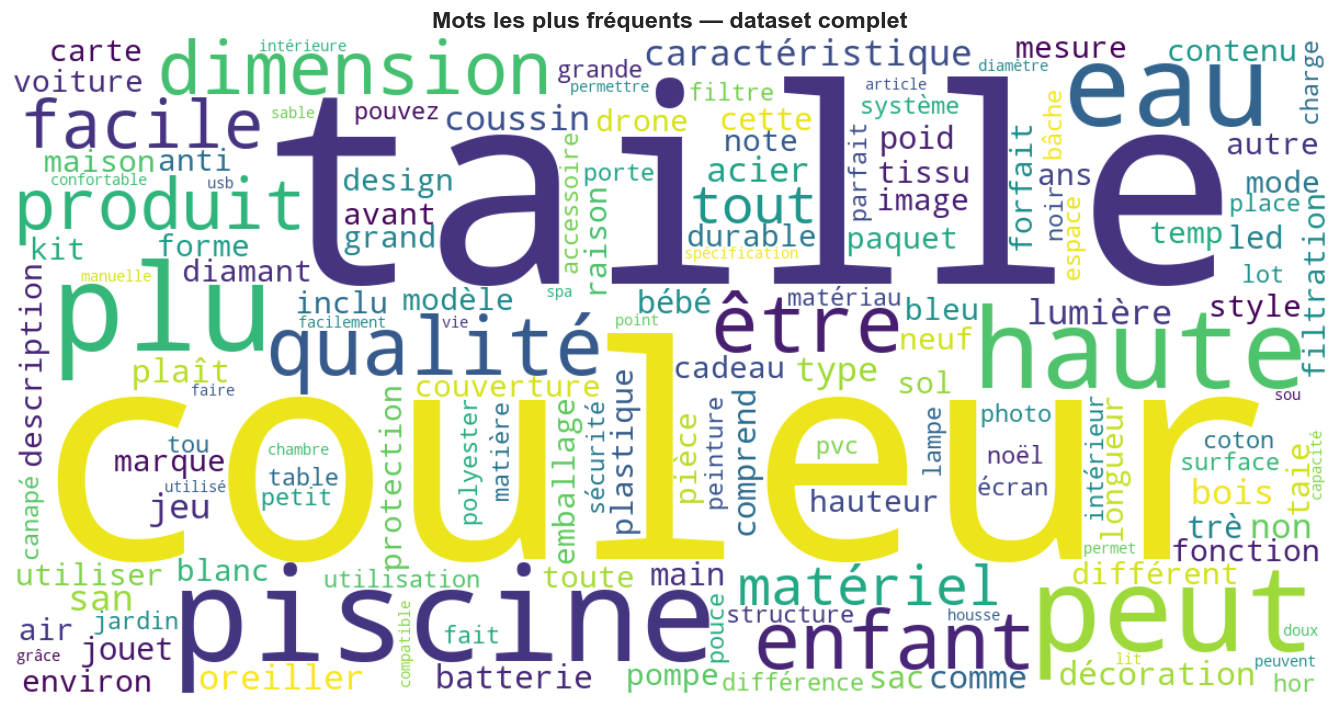

In [14]:
from nltk.corpus import stopwords as nltk_sw
import nltk
nltk.download('stopwords', quiet=True)

sw = (set(nltk_sw.words('french')) |
      set(nltk_sw.words('english')) |
      set(nltk_sw.words('dutch')))

def extraire_mots(texte):
    mots = re.findall(r'\b[a-zA-ZÀ-ÿ]{3,}\b', str(texte).lower())
    return [m for m in mots if m not in sw]

print("⏳ Extraction des mots")
df['mots'] = df['text'].apply(extraire_mots)
print("✅ Terminé")

# WordCloud global
tous_les_mots = ' '.join([m for liste in df['mots'] for m in liste])
wc = WordCloud(width=1200, height=600, background_color='white',
               colormap='viridis', max_words=150,
               collocations=False).generate(tous_les_mots)

plt.figure(figsize=(14, 6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title("Mots les plus fréquents — dataset complet", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '06_wordcloud_global.png', bbox_inches='tight')
plt.show()

## CELLULE 13 — Top mots par catégorie

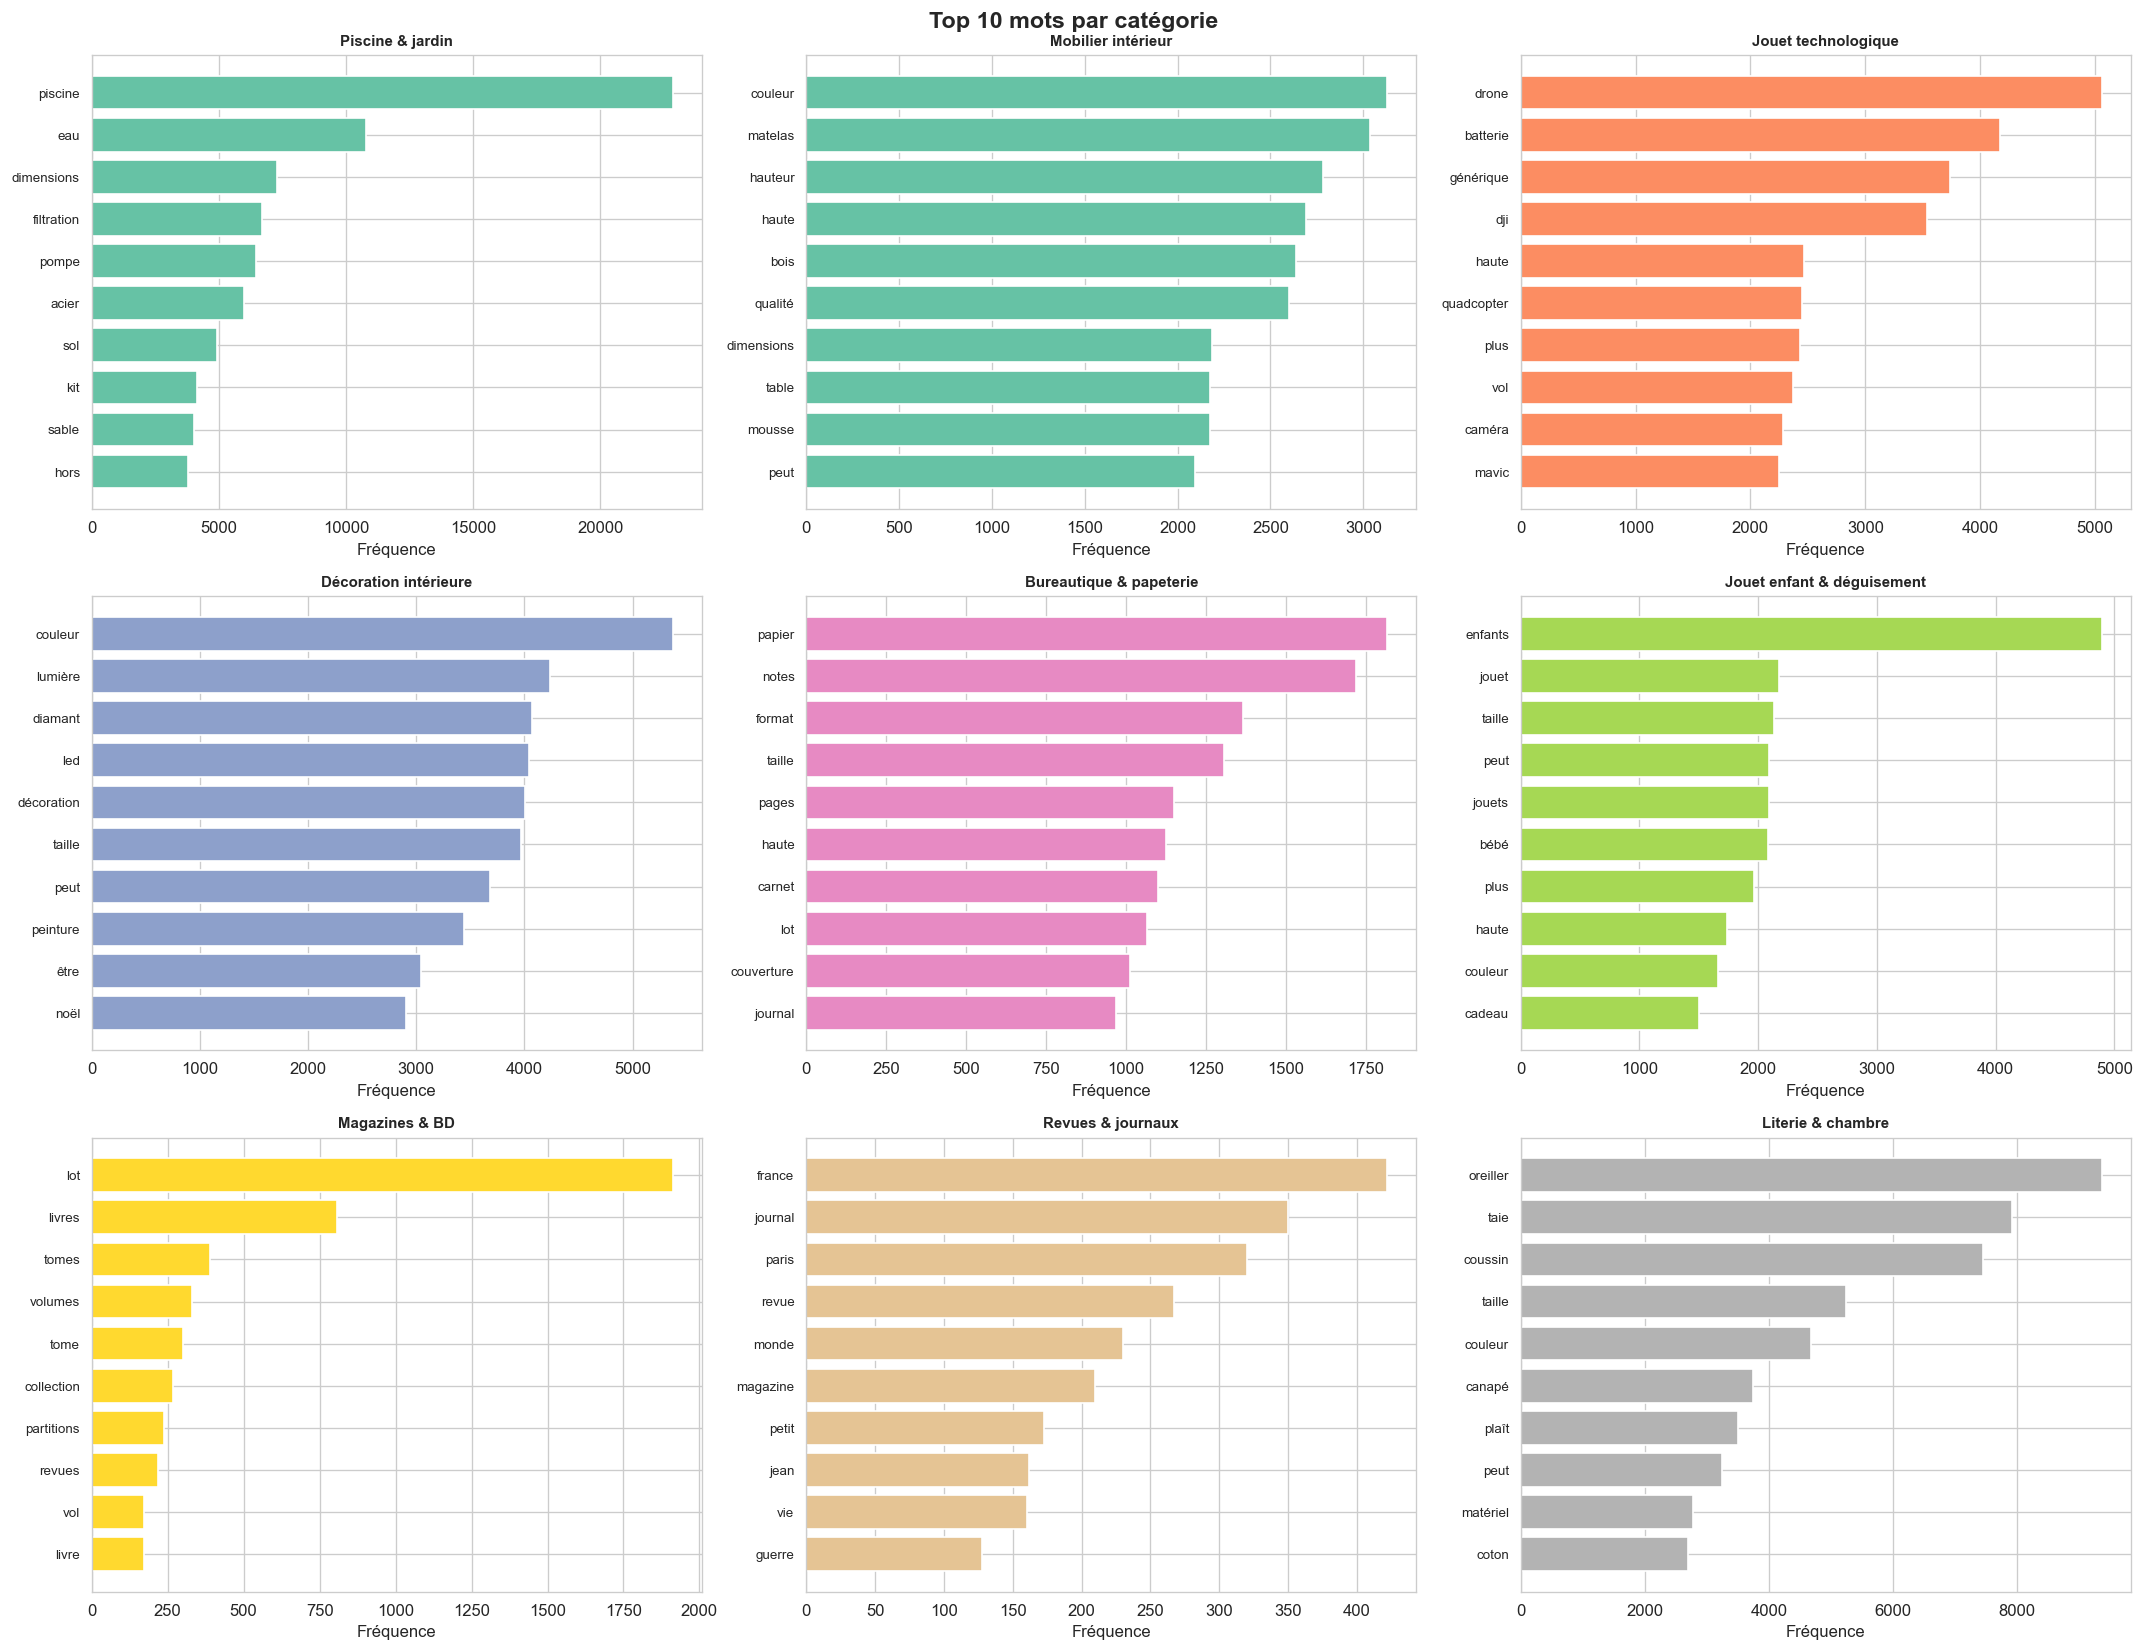

In [15]:
top_n = 10
N_CATS = 9  # top 9 catégories

top_cats = df['categorie'].value_counts().nlargest(N_CATS).index.tolist()
freq_par_cat = {
    cat: Counter([m for liste in df[df['categorie']==cat]['mots'] for m in liste])
    for cat in top_cats
}

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for i, cat in enumerate(top_cats):
    top_mots = pd.DataFrame(freq_par_cat[cat].most_common(top_n),
                             columns=['mot', 'freq'])
    axes[i].barh(top_mots['mot'][::-1], top_mots['freq'][::-1],
                 color=plt.cm.Set2(i/N_CATS))
    axes[i].set_title(cat, fontsize=9, fontweight='bold')
    axes[i].set_xlabel("Fréquence")
    axes[i].tick_params(axis='y', labelsize=8)

plt.suptitle(f"Top {top_n} mots par catégorie", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '07_top_mots_categories.png', bbox_inches='tight')
plt.show()

## CELLULE 14 — WordClouds par catégorie

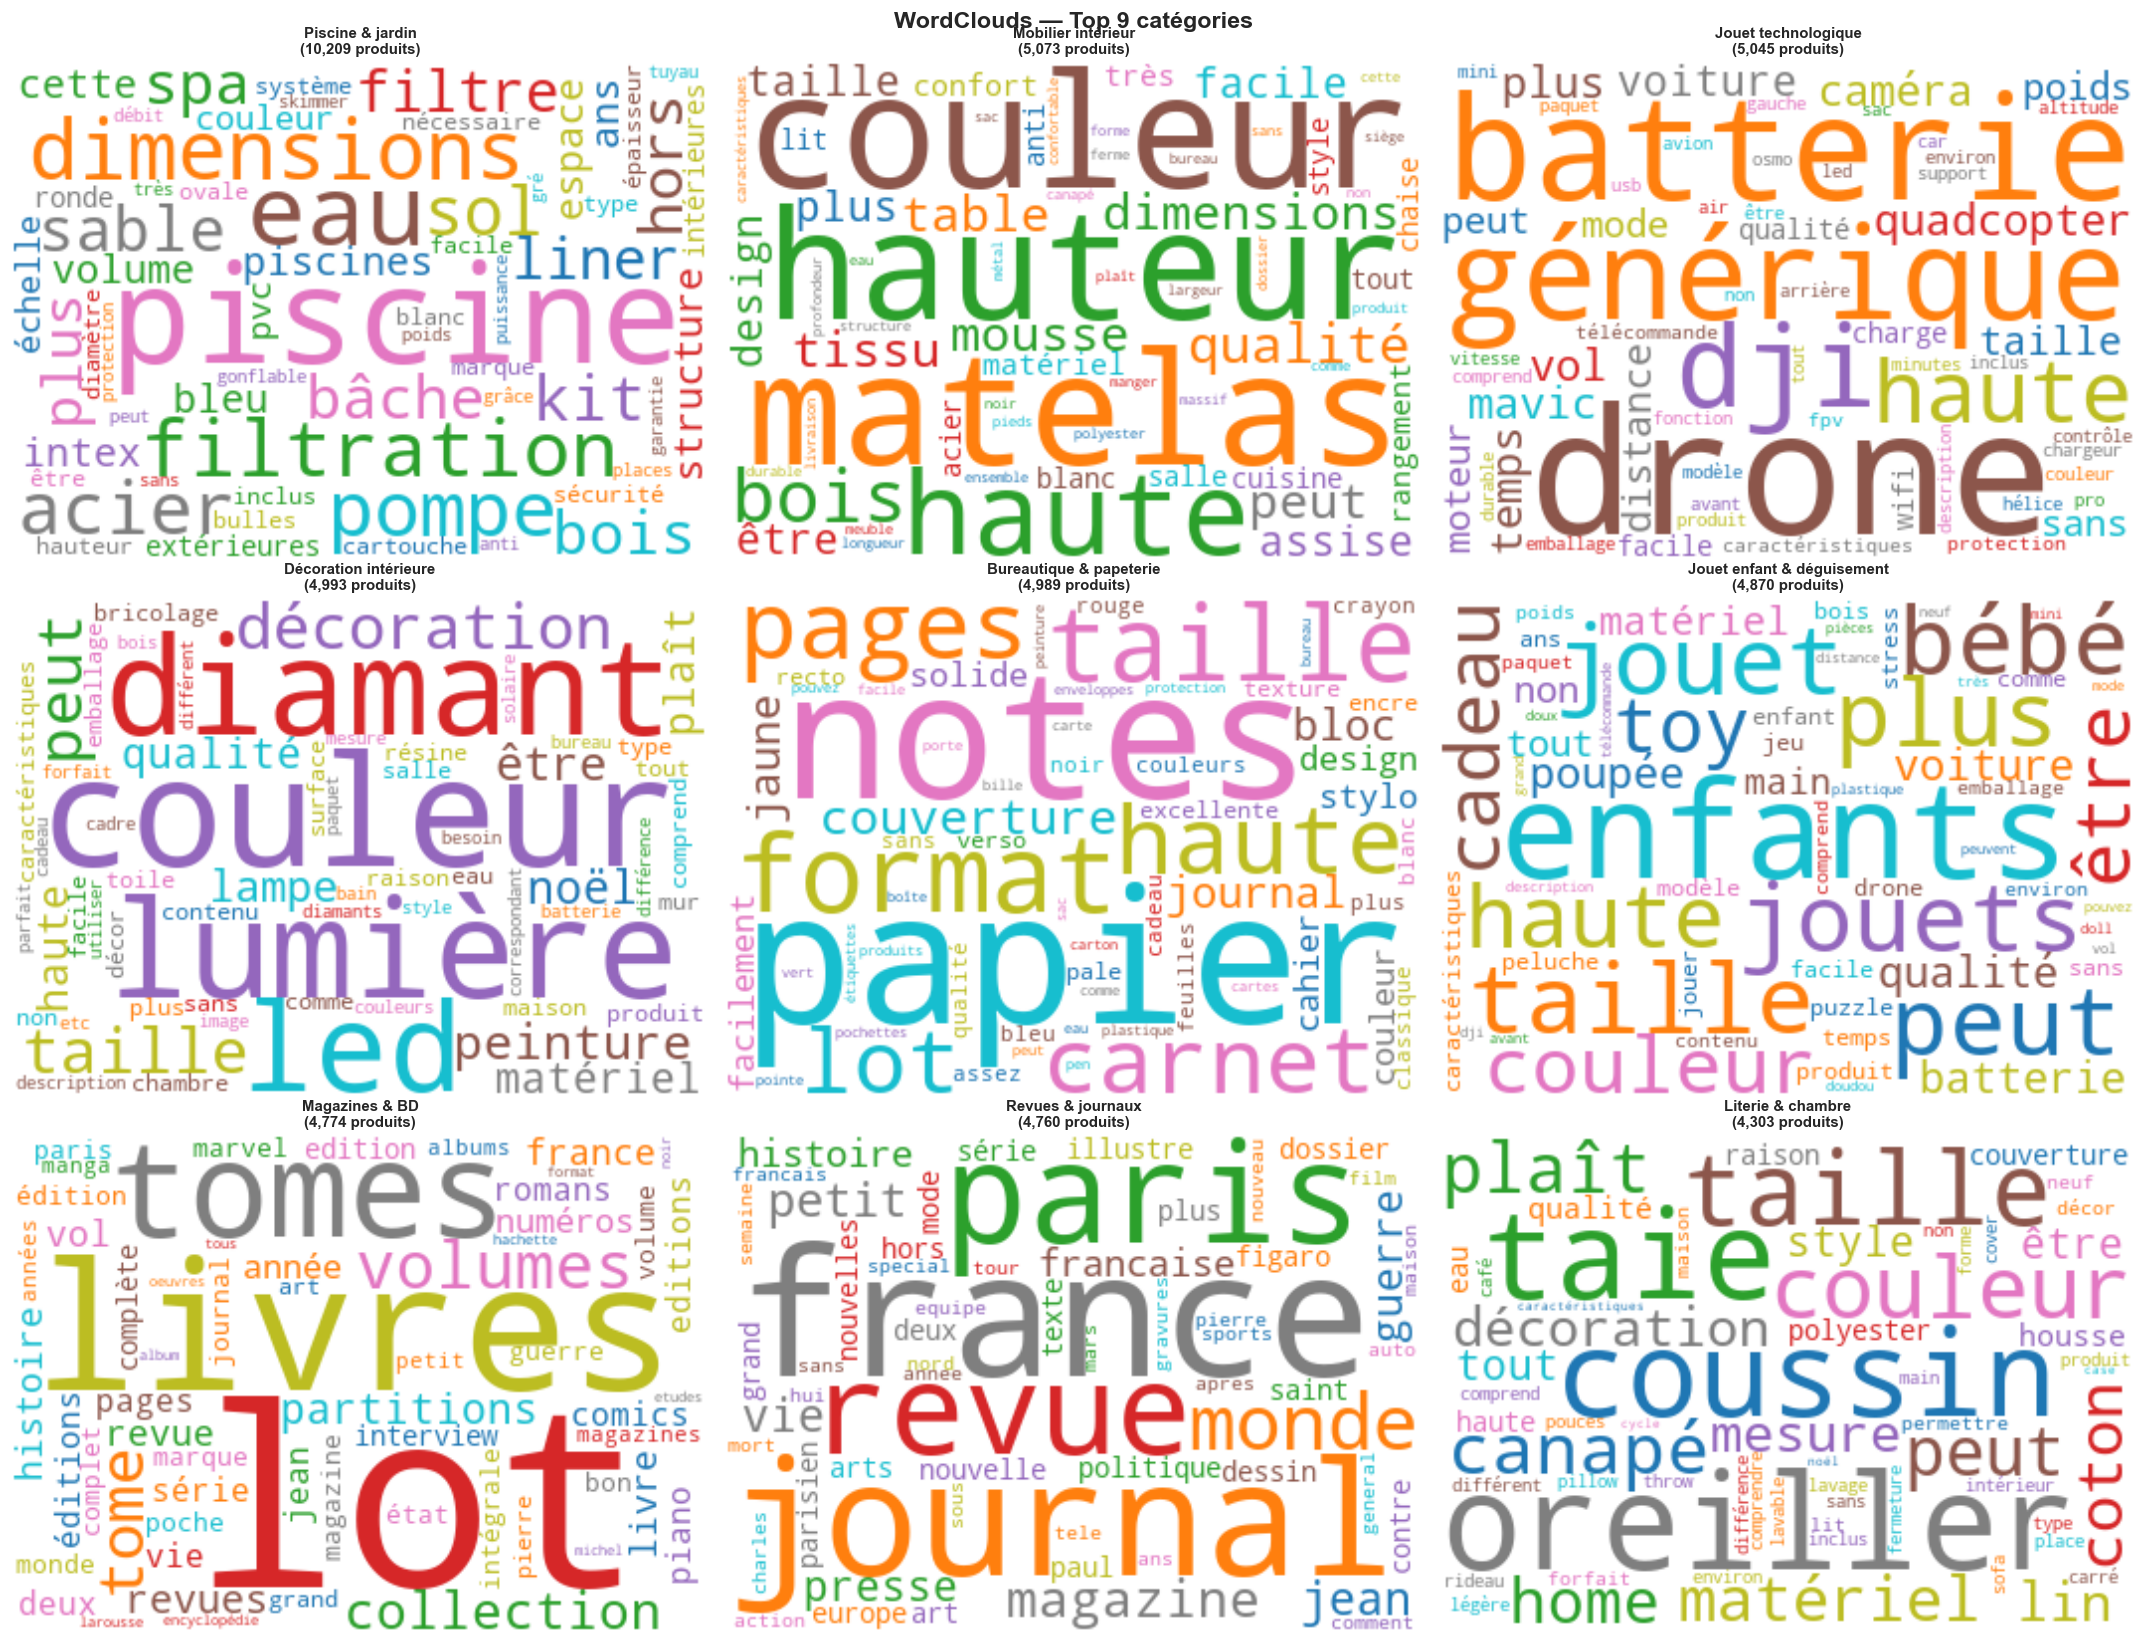

In [16]:
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for i, cat in enumerate(top_cats):
    wc = WordCloud(width=350, height=250, background_color='white',
                   colormap='tab10', max_words=60,
                   collocations=False).generate_from_frequencies(freq_par_cat[cat])
    axes[i].imshow(wc, interpolation='bilinear')
    axes[i].axis('off')
    n = (df['categorie'] == cat).sum()
    axes[i].set_title(f"{cat}\n({n:,} produits)", fontsize=9, fontweight='bold')

plt.suptitle("WordClouds — Top 9 catégories", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '08_wordclouds_categories.png', bbox_inches='tight')
plt.show()

## CELLULE 15 — Export

In [17]:
# Export du dataset nettoyé
cols_export = ['designation', 'description', 'text',
               'productid', 'imageid', 'prdtypecode', 'categorie', 'lang']
df[cols_export].to_csv(PROC_DIR / 'X_train_pre.csv')

print("✅ Fichiers exportés :")
for f in sorted(PROC_DIR.iterdir()):
    print(f"   {f.name:<30} {f.stat().st_size/1024:.0f} KB")

print(f"\n── Synthèse EDA ───────────────────────────────")
print(f"   Produits totaux        : {len(df):,}")
print(f"   Classes                : {df['prdtypecode'].nunique()}")
print(f"   Descriptions manquantes: {(df['description']=='').sum():,} ({(df['description']=='').mean()*100:.1f}%)")
print(f"   Langues détectées      : {df['lang'].nunique()}")
print(f"   Langue dominante       : français ({df['lang'].eq('fr').mean()*100:.1f}%)")
print(f"   Déséquilibre max/min   : {df['prdtypecode'].value_counts().max()}/{df['prdtypecode'].value_counts().min()}")

✅ Fichiers exportés :
   df_test_clean.csv              14963 KB
   df_train_clean.csv             93590 KB
   images_analysis.csv            3338 KB
   label_mapping.json             0 KB
   lang.csv                       2384 KB
   X_test_pre.csv                 15924 KB
   X_train_pre.csv                99704 KB

── Synthèse EDA ───────────────────────────────
   Produits totaux        : 84,916
   Classes                : 27
   Descriptions manquantes: 29,888 (35.2%)
   Langues détectées      : 31
   Langue dominante       : français (76.7%)
   Déséquilibre max/min   : 10209/764
